In [8]:
import pandas as pd
import numpy as np
import spacy
from spacy.pipeline import EntityRuler
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.utils import resample

In [2]:
nlp = spacy.load("en_core_web_sm")

In [4]:
def data_acquisition(file_path):
    """Charge le dataset et gère les valeurs manquantes avec NumPy."""
    df = pd.read_csv(file_path)
    # Remplacer les textes vides ou espaces par NaN
    df.replace(r'^/s*$', np.nan, regex=True, inplace=True)
    # Suppression des lignes où le contenu de l'article est absent (NaN)
    df.dropna(subset=['Content'], inplace=True)
    return df
data_acquisition("90minFootballTransferNewsNLP.csv").head()

,Title,Date,Link,Content
0,Football transfer rumours: Why Maguire's Man U...,"Aug 15, 2023",https://www.90min.com/posts/football-transfer-...,"90minÂ rounds up the latestÂ transfer news, ru..."
1,Chelsea agree Romeo Lavia fee with Southampton,"Aug 15, 2023",https://www.90min.com/posts/chelsea-agree-rome...,Chelsea have finalised an agreement with South...
2,Harry Maguire's proposed West Ham transfer col...,"Aug 15, 2023",https://www.90min.com/posts/harry-maguire-prop...,Harry Maguire's proposed transfer to West Ham ...
3,Southampton director breaks down Chelsea & Liv...,"Aug 15, 2023",https://www.90min.com/posts/southampton-direct...,Southampton director Jason Wilcox has revealed...
4,Neymar completes move from PSG to Al Hilal,"Aug 15, 2023",https://www.90min.com/posts/neymar-completes-m...,Saudi Pro League side Al Hilal have confirmed ...


In [5]:
def data_cleaning(text):
    """Nettoyage du texte brut (Suppression HTML, URLs, etc.)."""
    if pd.isna(text):
        return ""
    # Suppression balises HTML et liens HTTP
    text = re.sub(r'<.*?>|http\S+', '', str(text))
    # Suppression des caractères spéciaux mais conservation de la ponctuation utile
    text = re.sub(r'[^a-zA-Z0-9€$£\s.,\'àâäéèêëîïôöùûüçÀÂÄÉÈÊËÎÏÔÖÙÛÜÇ]', '', text)
    return text.strip()

In [11]:
import pandas as pd

# 1. Charger le fichier brut téléchargé sur Kaggle
# Assurez-vous d'avoir téléchargé 'players.csv' et 'clubs.csv'
df_players_raw = pd.read_csv("players.csv") 
df_clubs_raw = pd.read_csv("clubs.csv")

# 2. Extraire et standardiser les Joueurs
# On prend la colonne 'name' et on dit que ce sont des JOUEURS
df_p = df_players_raw[['name']].rename(columns={'name': 'Name'})
df_p['Type'] = 'JOUEUR'

# 3. Extraire et standardiser les Clubs
# On prend la colonne 'name' et on dit que ce sont des CLUBS
df_c = df_clubs_raw[['name']].rename(columns={'name': 'Name'})
df_c['Type'] = 'CLUB'

# 4. Fusionner les deux et mélanger
football_db = pd.concat([df_p, df_c], ignore_index=True)

# 5. Nettoyage final (supprimer les doublons et les valeurs vides)
football_db.dropna(inplace=True)
football_db.drop_duplicates(subset=['Name'], inplace=True)

# 6. Sauvegarder pour votre projet NLP
football_db.to_csv("football_db_clean.csv", index=False)

print(f"Dataset prêt ! {len(football_db)} entités trouvées.")
print(football_db.head(10))

Dataset prêt ! 32331 entités trouvées.
                  Name    Type
0       Miroslav Klose  JOUEUR
1   Roman Weidenfeller  JOUEUR
2     Dimitar Berbatov  JOUEUR
3                Lúcio  JOUEUR
4           Tom Starke  JOUEUR
5                 Dedê  JOUEUR
6  Christoph Metzelder  JOUEUR
7        Tomas Rosicky  JOUEUR
8         Marc Ziegler  JOUEUR
9     Roque Santa Cruz  JOUEUR


In [ ]:
def setup_model(nlp, joueurs_list, clubs_list):
    """
    Configure le modèle spaCy avec des listes de joueurs/clubs issues d'un dataset
    et des règles avancées pour les détails financiers et contractuels.
    """
    
    # 1. Ajout ou récupération de l'EntityRuler
    if "entity_ruler" not in nlp.pipe_names:
        # On le place AVANT le NER par défaut pour que nos listes soient prioritaires
        ruler = nlp.add_pipe("entity_ruler", before="ner")
    else:
        ruler = nlp.get_pipe("entity_ruler")
        
    patterns = []

    # 2. GÉNÉRATION DES PATTERNS POUR LES JOUEURS
    # On utilise "LOWER" pour que la détection ne soit pas sensible à la casse
    for name in joueurs_list:
        if isinstance(name, str) and len(name) > 2:
            patterns.append({
                "label": "PERSON", 
                "pattern": [{"LOWER": part.lower()} for part in name.split()]
            })

    # 3. GÉNÉRATION DES PATTERNS POUR LES CLUBS
    for club in clubs_list:
        if isinstance(club, str) and len(club) > 1:
            # Pattern pour le nom complet (ex: Arsenal Football Club)
            full_name_parts = club.split()
            patterns.append({
                "label": "CLUB", 
                "pattern": [{"LOWER": part.lower()} for part in full_name_parts]
            })
            
            # on ajoute aussi un pattern pour le premier mot seul
            if len(full_name_parts) > 1:
                main_name = full_name_parts[0]
                # On évite de rajouter des mots trop communs comme "FC" ou "Real"
                if main_name.lower() not in ["fc", "real", "atletico", "saint", "manchester"]:
                    patterns.append({
                        "label": "CLUB", 
                        "pattern": [{"LOWER": main_name.lower()}]
                    })

    # 4. RÈGLES ADDITIONNELLES (Prix, Contrats, Transactions)
    extra_patterns = [
        # Détection des prix (ex: 100M€, 50 million pounds, €80m)
        {"label": "MONEY", "pattern": [
                    {"IS_DIGIT": True}, 
                    {"LOWER": {"REGEX": r"^(m|million|m€|m\$|m£|€|\$|£)$"}}
                ]},
                # Cas où le symbole est devant (ex: €100m)
                {"label": "MONEY", "pattern": [
                    {"TEXT": {"REGEX": r"^[€\$£]"}},
                    {"IS_DIGIT": True},
                    {"LOWER": "m", "OP": "?"}
                ]},

        # Détection du type de transaction
        {"label": "DEAL_TYPE", "pattern": [
            {"LOWER": {"IN": ["permanent", "free", "temporary"]}, "OP": "?"}, 
            {"LOWER": {"IN": ["transfer", "loan", "signing", "deal"]}},
            {"LOWER": "with", "OP": "?"},
            {"LOWER": "option", "OP": "?"},
            {"LOWER": "to", "OP": "?"},
            {"LOWER": "buy", "OP": "?"}
        ]},        
        # Détection de la durée du contrat (ex: "until 2028")
        {"label": "CONTRAT_END", "pattern": [{"LOWER": "until"}, {"SHAPE": "dddd"}]},
        
        # Cas particuliers d'abréviations de clubs connus
        {"label": "CLUB", "pattern": [{"LOWER": "psg"}]},
        {"label": "CLUB", "pattern": [{"LOWER": "om"}]},
        {"label": "CLUB", "pattern": [{"LOWER": "ol"}]},
        {"label": "CLUB", "pattern": [{"LOWER": "man"}, {"LOWER": "utd"}]}
    ]
    
    # Ajouter toutes les règles au ruler
    patterns.extend(extra_patterns)
    ruler.add_patterns(patterns)
    
    return nlp

In [51]:
# 1. On récupère les listes depuis le dataframe créé précédemment
mes_joueurs = football_db[football_db['Type'] == 'JOUEUR']['Name'].tolist()
mes_clubs = football_db[football_db['Type'] == 'CLUB']['Name'].tolist()

# 2. Initialisation de spaCy
import spacy
nlp = spacy.load("en_core_web_sm")
# 3. On applique la configuration
nlp = setup_model(nlp, mes_joueurs, mes_clubs)

In [52]:
def data_extraction(text):
    doc = nlp(text)
    results = {
        "joueur": "Non trouvé",
        "club_actuel": "Non trouvé",
        "club_destination": "Non trouvé",
        "prix": "Non mentionné",
        "type_contrat": "Non mentionné"
    }
    
    # 1. Extraction propre des entités
    # On garde les clubs même si ce sont des stop words potentiels (ex: "The" devant un nom)
    # mais on vérifie que ce sont des noms propres (PROPN) ou des entités reconnues
    clubs_detectes = [
        ent for ent in doc.ents 
        if ent.label_ in ["CLUB", "ORG", "GPE"] 
        and not ent.text.lower() in ["the", "a", "an"] # Filtrage manuel simple
    ]
    
    for ent in doc.ents:
        # Nettoyage des parasites
        if ent.root.is_space or ent.root.is_punct:
            continue

        if ent.label_ == "PERSON" and results["joueur"] == "Non trouvé":
            results["joueur"] = ent.text
        elif ent.label_ == "MONEY":
            results["prix"] = ent.text
        elif ent.label_ == "DEAL_TYPE":
            results["type_contrat"] = ent.text

    # 2. Analyse de proximité avec les attributs spaCy
    if len(clubs_detectes) == 1:
        results["club_destination"] = clubs_detectes[0].text
    elif len(clubs_detectes) >= 2:
        for club in clubs_detectes:
            # On récupère les tokens de contexte
            # .nbor(-1) permet de regarder le mot juste avant
            try:
                # On regarde jusqu'à 3 mots avant l'entité
                start_idx = max(0, club.start - 3)
                contexte_tokens = doc[start_idx:club.start]
                contexte_mots = [t.lower_ for t in contexte_tokens if not t.is_punct]
                
                # Logique vendeur (quitte / vient de)
                if any(m in contexte_mots for m in ["from", "leaves", "of", "departure"]):
                    results["club_actuel"] = club.text
                
                # Logique acheteur (rejoint / signe pour)
                elif any(m in contexte_mots for m in ["to", "joins", "signs", "for", "signing"]):
                    results["club_destination"] = club.text
            except:
                continue

    # 3. Sécurité ultime : si destination est vide, on prend le premier club non utilisé
    if results["club_destination"] == "Non trouvé" and len(clubs_detectes) > 0:
        for c in clubs_detectes:
            if c.text != results["club_actuel"]:
                results["club_destination"] = c.text
                break
                
    return results

In [ ]:
# Charger le modèle anglais léger
nlp = spacy.load("en_core_web_sm", disable=['ner', 'parser']) 
df = pd.read_csv("90minFootballTransferNewsNLP.csv")
def lemmatization(text):
    doc = nlp(str(text).lower())
    # On récupère le lemme de chaque mot s'il n'est pas une ponctuation
    return " ".join([token.lemma_ for token in doc if not token.is_punct])
# --- 1. FONCTION DE LABELING AMÉLIORÉE (FOCUS DÉBUT DE TEXTE) ---
def auto_labeling(row):
    # On combine Titre et Début du contenu car l'info principale est là
    text = (str(row['Title']) + " " + str(row['Content'])).lower()
    lemmatized_context = lemmatization(text)
    # On regarde surtout les 300 premiers caractères (le "lead" journalistique)
    
    # Listes de mots-clés
    failed_words = ["collapsed", "rejected", "failed", "called off", "deal off", "no agreement", "snubbed", "turned down"]
    official_words = ["finalised", "confirmed", "official", "signed", "unveiled", "here we go", "agreed a fee", "medical tests","done","set to","join","agree"]
    doubt_words = ["linked with", "monitoring", "interest in", "speculation", "target", "reports suggest", "negotiations","interested","talk","contact","meeting","approach"]

    # LOGIQUE DE PRIORITÉ : ÉCHEC > RUMEUR > OFFICIEL
    if any(word in lemmatized_context for word in failed_words):
        return "ÉCHEC"
    if any(word in lemmatized_context for word in doubt_words):
        return "RUMEUR"
    if any(word in lemmatized_context for word in official_words):
        return "OFFICIEL"
    return "RUMEUR"

# Application sur le DataFrame original
df['category'] = df.apply(auto_labeling, axis=1)

# --- 2. ÉQUILIBRAGE (RE-SAMPLING) ---
n_cible = 2000
df_rumeur = df[df.category == "RUMEUR"]
df_officiel = df[df.category == "OFFICIEL"]
df_echec = df[df.category == "ÉCHEC"]

df_rumeur_bal = resample(df_rumeur, replace=False, n_samples=n_cible, random_state=42)
df_officiel_bal = resample(df_officiel, replace=True, n_samples=n_cible, random_state=42)
df_echec_bal = resample(df_echec, replace=True, n_samples=n_cible, random_state=42)

df_balanced = pd.concat([df_rumeur_bal, df_officiel_bal, df_echec_bal])

# --- 3. PRÉPARATION DES DONNÉES (X = TITRE + DÉBUT CONTENU) ---
# L'IA se trompe moins si elle ne lit que l'essentiel
df_balanced['Features'] = df_balanced['Title'] + " " + df_balanced['Content'].apply(lemmatization)

X = df_balanced['Features'].astype(str)
y = df_balanced['category']

# --- 4. VECTORISATION ET ENTRAÎNEMENT ---
vectorizer = TfidfVectorizer(stop_words='english', max_features=3000, ngram_range=(1, 2))
X_vectorized = vectorizer.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_vectorized, y, test_size=0.2, random_state=42)

print("⏳ Entraînement du modèle optimisé...")
clf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
clf.fit(X_train, y_train)

# --- 5. ÉVALUATION ---
y_pred = clf.predict(X_test)
print(f"✅ Précision finale : {accuracy_score(y_test, y_pred):.2f}")
print("\n--- Nouveau Rapport de Classification ---")
print(classification_report(y_test, y_pred))

⏳ Entraînement du modèle optimisé...
✅ Précision finale : 0.95

--- Nouveau Rapport de Classification ---
              precision    recall  f1-score   support

    OFFICIEL       0.90      0.97      0.93       380
      RUMEUR       0.97      0.90      0.93       437
       ÉCHEC       1.00      1.00      1.00       383

    accuracy                           0.95      1200
   macro avg       0.95      0.96      0.95      1200
weighted avg       0.96      0.95      0.95      1200



In [46]:
# 1. Filtrer pour ne garder que les officialS
df_officiel = df_balanced[df_balanced['category'] == "OFFICIEL"]

# 2. Afficher le nombre d'articles trouvés
print(f"📊 Nombre total d'articles classés en 'officiel' : {len(df_officiel)}")
print("-" * 50)

# 3. Affichage pour vérification
pd.set_option('display.max_colwidth', 200) # On élargit pour bien lire le début du texte

# On affiche 10 lignes au hasard pour voir la diversité des officials
if len(df_officiel) >= 10:
    display_df = df_officiel[['Title', 'Content', 'category']].sample(10, random_state=1)
else:
    display_df = df_officiel[['Title', 'Content', 'category']]

print("🔍 Échantillon de vérification des officialS :")
display(display_df)

📊 Nombre total d'articles classés en 'officiel' : 2000
--------------------------------------------------
🔍 Échantillon de vérification des officialS :


,Title,Content,category
4442,Summer transfer window 2021: When does it open and close?,"As the season enters the home straight there's a tendency for us all to get a bit upset as we realise we'll have to go a few months without watching our beloved clubs. However, a few days later yo...",OFFICIEL
5539,Fulham Complete Loan Signing of Ademola Lookman From RB Leipzig,Fulham have confirmed the loan signing of Ademola Lookman from RB Leipzig for the 2020/21 season. Lookman failed to impress in 2019/20 after completing a permanent move to Leipzig for around Â£22...,OFFICIEL
6293,Florentino Perez Admits Real Madrid Can't Afford Major Signings This Summer,"Real Madrid president Florentino Perez has said the club are still feeling the full effects of the coronavirus crisis, and there will be no major incoming transfer business as a result. Los Blanc...",OFFICIEL
4209,Reports conflict over option to buy details of William Saliba's Marseille loan,"Arsenal centre back William Saliba is set to join Marseille on loan for the upcoming season, but one report has suggested the French side may have negotiated themselves an option to buy Saliba per...",OFFICIEL
9,Kepa Arrizabalaga reveals desire to seal permanent Real Madrid transfer,Kepa Arrizabalaga has confirmed he hopes to seal a permanent move to Real Madrid after joining the Spanish side on an initial loan from Chelsea. After Thibaut Courtois went down with a serious kne...,OFFICIEL
4948,Moussa Dembele set to join Atletico Madrid on loan,"Lyon striker Moussa Dembele looks set to sign for Atletico Madrid on loan, with a Â£30m fee agreed between the two clubs should the La Liga leaders opt to make the move permanent. Diego Simeone ha...",OFFICIEL
1599,What is a Premier League deal sheet?,"Signing a player on a tight deadline is a complicated process for clubs, but can be made easier by the use of a deal sheet. For a player to move from one club to another, a considerable amount of ...",OFFICIEL
4233,Players who are officially out of contract on June 30,"30 June is here. You know what that means? It's free agency season. For all the players who have not been able to convince their clubs to hand them an extra year, the search for a new employer has...",OFFICIEL
6147,Chris Smalling Set for Man Utd Return Before Europa League Denouement,"Chris Smalling is set for a return to Manchester United, with Roma yet to reach an agreement with the club over extending his loan for the conclusion of the Europa League. The Englishman shone for...",OFFICIEL
5167,Newcastle Eyeing Loan Move for Manchester United's Brandon Williams,"Newcastle are monitoring Manchester United full-back Brandon Williams with a view to taking the youngster on loan in January. Williams enjoyed a breakthrough year at Old Trafford last season, maki...",OFFICIEL


In [53]:
def predict_article_category(text):
    """
    Reçoit un texte brut, le lemmatise avec SpaCy, 
    le vectorise, et prédit sa catégorie.
    """
    # 1. Lemmatisation (pour transformer "rejected" en "reject", etc.)
    # On utilise la même logique que pour l'entraînement
    doc = nlp(str(text).lower())
    text_lem = " ".join([token.lemma_ for token in doc if not token.is_punct])
    
    # 2. Vectorisation (avec le vectoriseur déjà entraîné)
    vec = vectorizer.transform([text_lem]) 
    
    # 3. Prédiction
    prediction = clf.predict(vec)[0]
    
    # 4. Probabilité
    proba = clf.predict_proba(vec).max()
    
    return prediction, proba

# --- TEST AVEC TEXTE BRUT ---
nouvel_article = "Fulham Complete Loan Signing of Ademola Lookman From RB Leipzig"

cat, conf = predict_article_category(nouvel_article)

print(f"📝 Texte original : {nouvel_article}")
print(f"🤖 Résultat IA : {cat}")
print(f"🎯 Confiance : {conf:.0%}")

📝 Texte original : Fulham Complete Loan Signing of Ademola Lookman From RB Leipzig
🤖 Résultat IA : OFFICIEL
🎯 Confiance : 81%


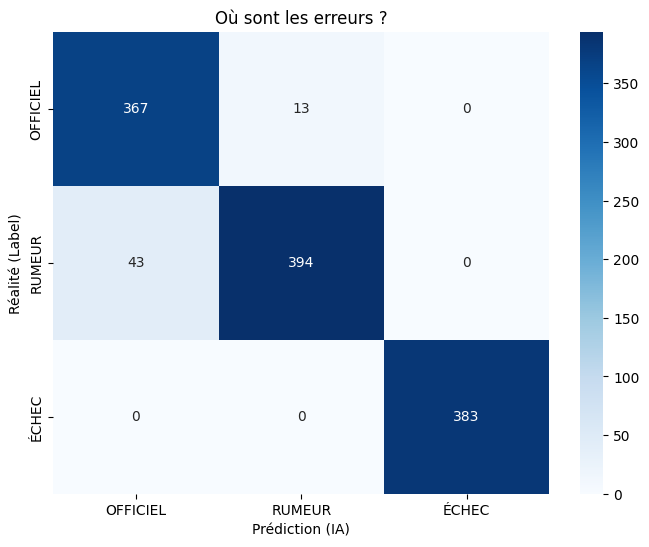

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Calcul de la matrice
cm = confusion_matrix(y_test, y_pred)

# Affichage graphique
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=clf.classes_, 
            yticklabels=clf.classes_)
plt.xlabel('Prédiction (IA)')
plt.ylabel('Réalité (Label)')
plt.title('Où sont les erreurs ?')
plt.show()